This notebook walks through the steps that the likelihood PID metric performs in order to showcase each step along the way. This will primarily be split into two sections: 

1. Bare Likelihood PID (No residual range correction), $\ell_0$

2. Residual range corrected Likelihood PID, $\ell$

In [1]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

import sys

sys.path.insert(0, "/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/root-6.28.12-vgs6mjswsg36hl3oarsrsyc2dcua6khe/lib/root")
import ROOT


import glob, os, re
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
from pyanalib.split_df_helpers import get_n_split
from pyanalib.pandas_helpers import multicol_merge

import makedf.llpid as llpid
import importlib
importlib.reload(llpid)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

import warnings
warnings.filterwarnings('ignore')


Welcome to JupyROOT 6.28/12


# 1. Bare Likelihood PID

The following cells are either commented out or not; you can uncomment out particular cells to see different features of the likelihood fitting. The first cell below shows a well behaved track proton and the following cells show tracks with worse behaved in different ways.  

In [ ]:
#Good high nhit, no rr correction needed track: Everything gets it right
# file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_5.df"
# params = llpid.LLPID_PARAMS
# COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
# PDG, TRUE_HYP = 2212, "p"                                      # (13, "mu") or (211, "pi") for another species

# evt     = pd.read_hdf(file, key="/evt_0")
# hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# # Find a good demonstrative track where we can clearly see the benefit of residual range correction
# pdg       = evt["pfp", "trk", "truth", "p", "pdg"]
# contained = evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1
# # stopped   = ~evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])
# start_dist = np.sqrt(sum((evt["pfp", "trk", "start", a] - evt["pfp", "trk", "truth", "p", "start", a])**2 for a in "xyz"))
# end_dist   = np.sqrt(sum((evt["pfp", "trk", "end", a]   - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))
# good = (np.abs(pdg) == PDG) & contained  & (evt["pfp", "trk", "len"] >15 ) #& (start_dist < 2) & (end_dist > 15)  & (evt["pfp", "trk", "len"] <25 )

# trk    = evt.index[good][0]                                    # change [0] to look at another track
# hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
# print("track", trk, "  true pdg", pdg[trk])
# print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
# print("hits per plane:", [len(df) for df in hitdfs])


track (0, 3, 0, 1)   true pdg 2212
reco length 49.3 cm,  reco end is 0.1 cm from the true end
hits per plane: [13, 67, 106]


In [112]:
# # Shows a reversed track
# file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_4.df"
# params = llpid.LLPID_PARAMS
# COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
# PDG, TRUE_HYP = 2212, "p"                                      # (13, "mu") or (211, "pi") for another species

# evt     = pd.read_hdf(file, key="/evt_0")
# hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# # Find a good demonstrative track where we can clearly see the benefit of residual range correction
# pdg       = evt["pfp", "trk", "truth", "p", "pdg"]
# contained = evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1
# # stopped   = ~evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])
# start_dist = np.sqrt(sum((evt["pfp", "trk", "start", a] - evt["pfp", "trk", "truth", "p", "start", a])**2 for a in "xyz"))
# end_dist   = np.sqrt(sum((evt["pfp", "trk", "end", a]   - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))
# good = (np.abs(pdg) == PDG) & contained  & (evt["pfp", "trk", "len"] >15 ) #& (start_dist < 2) & (end_dist > 15)  & (evt["pfp", "trk", "len"] <25 )

# trk    = evt.index[good][0]                                    # change [0] to look at another track
# hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
# print("track", trk, "  true pdg", pdg[trk])
# print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
# print("hits per plane:", [len(df) for df in hitdfs])


In [52]:
# #Good track showing rr correction: Bare LLPID and chi2 mis-classify, but rr-corrected LLPID gets it correct
file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_12.df"
params = llpid.LLPID_PARAMS
COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
PDG, TRUE_HYP = 2212, "p"                                      # (13, "mu") or (211, "pi") for another species

evt     = pd.read_hdf(file, key="/evt_0")
hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# a contained, stopping track whose reco start is on the true start, but whose reco end stops
# 5-20 cm short of the true end: the rr correction should find that missing length
pdg       = evt["pfp", "trk", "truth", "p", "pdg"]
contained = evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1
# stopped   = ~evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])
start_dist = np.sqrt(sum((evt["pfp", "trk", "start", a] - evt["pfp", "trk", "truth", "p", "start", a])**2 for a in "xyz"))
end_dist   = np.sqrt(sum((evt["pfp", "trk", "end", a]   - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))
good = (np.abs(pdg) == PDG) & contained  & (start_dist < 2) & (end_dist > 15) & (end_dist < 30) & (evt["pfp", "trk", "len"] > 30)

trk    = evt.index[good][0]                                    # change [0] to look at another track
hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
print("track", trk, "  true pdg", pdg[trk])
print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
print("hits per plane:", [len(df) for df in hitdfs])


track (6, 1, 0, 1)   true pdg 2212
reco length 33.1 cm,  reco end is 27.3 cm from the true end
hits per plane: [64, 36, 100]


In [ ]:
# A true muon where the proton hypothesis wins by having dL very large to simulate a MIP proton
# Justifies the use of flatness parameter to reject fits
# file   = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_1036.df"
# params = llpid.LLPID_PARAMS
# COLOR  = {"p": "#2a78d6", "mu": "#eb6834", "pi": "#1baf7a"}   # one colour per hypothesis in every plot
# PDG, TRUE_HYP = 13, "mu"

# evt     = pd.read_hdf(file, key="/evt_0")
# hit_dfs = [pd.read_hdf(file, key=f"/hit{plane}_0") for plane in range(3)]

# pdg      = evt["pfp", "trk", "truth", "p", "pdg"]
# end_dist = np.sqrt(sum((evt["pfp", "trk", "end", a] - evt["pfp", "trk", "truth", "p", "end", a])**2 for a in "xyz"))

# trk    = (37, 12, 0, 0)
# hitdfs = [df[df.index.droplevel(-1).isin([trk])] for df in hit_dfs]
# print("track", trk, "  true pdg", pdg[trk], "  end process", evt["pfp", "trk", "truth", "p", "end_process"][trk])
# print("reco length", round(evt["pfp", "trk", "len"][trk], 1), "cm,  reco end is", round(end_dist[trk], 1), "cm from the true end")
# print("hits per plane:", [len(df) for df in hitdfs])

# # the flat-fit flag on vs off
# for name, fa in [(f"flag on  (flat_abs = {params['flat_abs']:g})", params["flat_abs"]), ("flag off (flat_abs = 0)", 0.0)]:
#     r = llpid.likelihood(hitdfs, params=dict(params, flat_abs=fa)).iloc[0]
#     ells = {h: r["ell_" + h] for h in llpid.HYPS}
#     print(f"{name}:  " + "  ".join(f"ell_{h} {v:8.1f} (dL {r['dl_' + h]:4.0f}, flat {bool(r['flattened_' + h])})" for h, v in ells.items())
#           + f"   ->  {min(ells, key=ells.get)}")


track (37, 12, 0, 0)   true pdg 13   end process 41
reco length 222.3 cm,  reco end is 10.6 cm from the true end
hits per plane: [465, 180, 645]
flag on  (flat_abs = 10):  ell_mu   1265.6 (dL   20, flat False)  ell_pi   1274.1 (dL   27, flat False)  ell_p   8973.1 (dL    0, flat True)   ->  mu
flag off (flat_abs = 0):  ell_mu   1265.6 (dL   20, flat False)  ell_pi   1274.1 (dL   27, flat False)  ell_p   1221.3 (dL  468, flat False)   ->  p


Having a look at the dE/dx vs residual range for this given track

usable hits per plane: [60, 33, 95]   total: 188


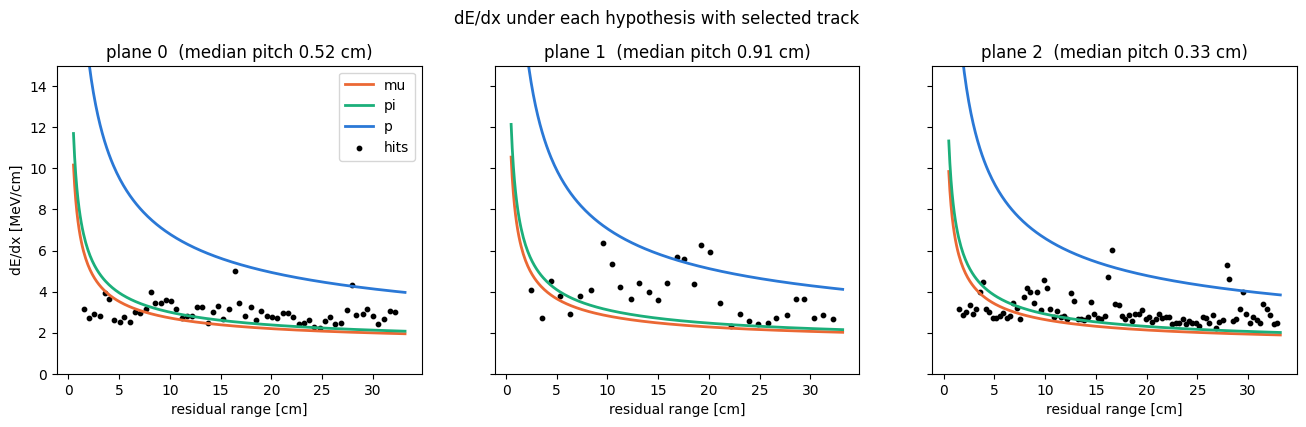

In [53]:
tracks = llpid._track_index(hitdfs)
planes = [llpid._prepare_plane(df, tracks, llpid._plane_of(df, i, len(hitdfs)), "dedx", params)
          for i, df in enumerate(hitdfs)]
n_hits = sum(h["n_usable"] for h in planes)
print("usable hits per plane:", [int(h["n_usable"][0]) for h in planes], "  total:", int(n_hits[0]))


rr_grid = np.linspace(0.5, max(hits["rr"].max() for hits in planes), 300)
rr_max = np.nanmedian([llpid._per_track_max(h, h["rr"]) for h in planes], axis=0)
for h in planes:
    h["rr_max"] = rr_max[h["tid"]]

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for hits, a in zip(planes, ax):
    pitch = np.median(hits["pitch"])
    for hyp in llpid.HYPS:
        KE = llpid._ke_from_rr(llpid._ke_table(hyp), rr_grid)
        xi, kappa, beta2, dedx_lam0 = llpid._pdf_params(KE, llpid.MASS[hyp], pitch)
        a.plot(rr_grid, dedx_lam0, color=COLOR[hyp], lw=2, label=hyp)
    a.scatter(hits["rr"][hits["usable"]], hits["dedx"][hits["usable"]], s=10, c="k", label="hits")
    a.set(xlabel="residual range [cm]", title=f"plane {hits['plane']}  (median pitch {pitch:.2f} cm)", ylim=(0, 15))
ax[0].set_ylabel("dE/dx [MeV/cm]"); ax[0].legend()
fig.suptitle("dE/dx under each hypothesis with selected track", y=1.02)
plt.show()


In [54]:
tables_bare = llpid._load_tables(params["tables_bare"])

per_hit = {}
for hyp in llpid.HYPS:
    frames = []
    for hits in planes:
        KE = llpid._ke_from_rr(llpid._ke_table(hyp), hits["rr"])
        xi, kappa, beta2, dedx_lam0 = llpid._pdf_params(KE, llpid.MASS[hyp], hits["pitch"])
        table = llpid._table_for(tables_bare, hits["plane"], hyp)
        pdf   = llpid._hit_pdf(hits["dedx"], hits["pitch"], KE, llpid.MASS[hyp], table)
        frames.append(pd.DataFrame({"plane": hits["plane"], "rr": hits["rr"], "dedx": hits["dedx"], "KE": KE,
                                    "lambda": (hits["dedx"] - dedx_lam0) / xi,      # same line as in _hit_pdf
                                    "kappa": kappa, "beta2": beta2,
                                    "pdf": pdf, "-2ln(pdf)": -2 * np.log(pdf)})[hits["usable"]])
    per_hit[hyp] = pd.concat(frames, ignore_index=True)


print("Muon Hypothesis")
print(per_hit['mu'].head(), "\n")

print("Proton Hypothesis")
print(per_hit['p'].head())


Muon Hypothesis
   plane        rr      dedx         KE    lambda     kappa     beta2  \
0      0  1.554243  3.138517  15.509565 -6.768953  0.642306  0.239617   
1      0  2.073773  2.705965  18.325583 -6.898654  0.470325  0.273766   
2      0  2.523427  2.899592  20.546926 -5.588774  0.380585  0.299105   
3      0  3.071872  2.825860  23.062331 -5.031762  0.307845  0.326231   
4      0  3.596764  3.952230  25.317959 -0.257540  0.259593  0.349238   

        pdf  -2ln(pdf)  
0  0.074064   5.205661  
1  0.064752   5.474369  
2  0.081687   5.009718  
3  0.127789   4.114750  
4  0.543026   1.221197   

Proton Hypothesis
   plane        rr      dedx         KE     lambda     kappa     beta2  \
0      0  1.554243  3.138517  40.137630 -11.956991  6.838051  0.080364   
1      0  2.073773  2.705965  47.187715 -11.951265  4.984847  0.093475   
2      0  2.523427  2.899592  52.683645 -11.460425  4.023420  0.103502   
3      0  3.071872  2.825860  58.838724 -11.216637  3.247581  0.114536   
4    

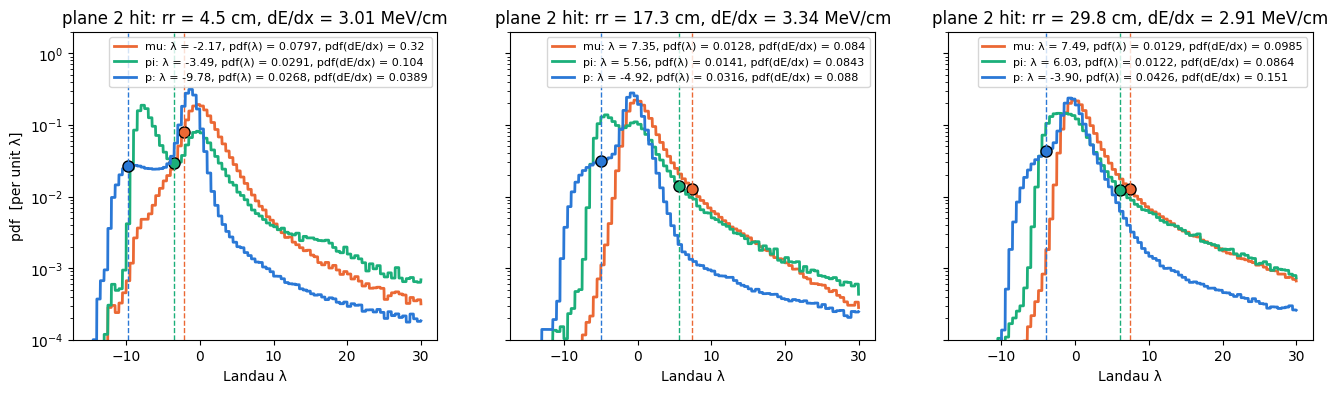


  mu
     plane         rr      dedx         KE    lambda     kappa     beta2       pdf  -2ln(pdf)
102      2   4.504839  3.012341  28.958630 -2.172194  0.130887  0.383961  0.319594   2.281406
140      2  17.275763  3.338954  67.376160  7.349854  0.030001  0.627143  0.083977   4.954432
178      2  29.829309  2.913661  97.940637  7.494223  0.016001  0.730687  0.098510   4.635196

  pi
     plane         rr      dedx          KE    lambda     kappa     beta2       pdf  -2ln(pdf)
102      2   4.504839  3.012341   32.416367 -3.485485  0.176365  0.341438  0.103741   4.531711
140      2  17.275763  3.338954   74.175929  5.564675  0.040820  0.573627  0.084337   4.945879
178      2  29.829309  2.913661  106.631822  6.034606  0.022011  0.678632  0.086405   4.897413

  p
     plane         rr      dedx          KE    lambda     kappa     beta2       pdf  -2ln(pdf)
102      2   4.504839  3.012341   72.990045 -9.782815  1.377335  0.139145  0.038936   6.491654
140      2  17.275763  3.338954  157.

In [55]:
hits  = planes[2]
used  = np.flatnonzero(hits["usable"])
picks = used[[len(used) // 10, len(used) // 2, 9 * len(used) // 10]]   # 10%, 50% and 90% of the way along the track
lam_grid = np.linspace(-15, 30, 1500)

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for i, a in zip(picks, ax):
    rr, dedx, pitch = hits["rr"][i], hits["dedx"][i], hits["pitch"][i]
    for hyp in llpid.HYPS:
        KE    = llpid._ke_from_rr(llpid._ke_table(hyp), rr)
        table = llpid._table_for(tables_bare, hits["plane"], hyp)
        xi_per_cm, kappa, beta2, mpv_shift = llpid._pdf_params(KE, llpid.MASS[hyp], pitch)
        lam = float(np.clip((dedx - mpv_shift) / xi_per_cm, -50.0, 100.0))   # this hit's Landau lambda under hyp

        kap = np.full_like(lam_grid, kappa)
        bet = np.full_like(lam_grid, beta2)
        curve = llpid._lookup_binned(lam_grid, kap, bet, table)                              # pdf(lambda | kappa, beta2)
        value = float(llpid._lookup_binned(np.array([lam]), kap[:1], bet[:1], table)[0])     # where the hit lands on it

        a.plot(lam_grid, curve, color=COLOR[hyp], lw=2,
               label=f"{hyp}: λ = {lam:.2f}, pdf(λ) = {value:.3g}, pdf(dE/dx) = {value / float(xi_per_cm):.3g}")
        a.plot(lam, value, "o", ms=8, color=COLOR[hyp], markeredgecolor="k")
        a.axvline(lam, color=COLOR[hyp], lw=1, ls="--")
    a.set(xlabel="Landau λ", yscale="linear", ylim=(0, None),
          title=f"plane {hits['plane']} hit: rr = {rr:.1f} cm, dE/dx = {dedx:.2f} MeV/cm")
    a.legend(fontsize=8)
    a.set_yscale("log"); a.set_ylim(1e-4, 2)
ax[0].set_ylabel("pdf  [per unit λ]")

plt.show()

# the same hits in the per-hit table from 1c
for hyp in llpid.HYPS:
    t = per_hit[hyp]
    print("\n ",hyp); print(t[(t["plane"] == hits["plane"]) & t["rr"].isin(hits["rr"][picks])].to_string())


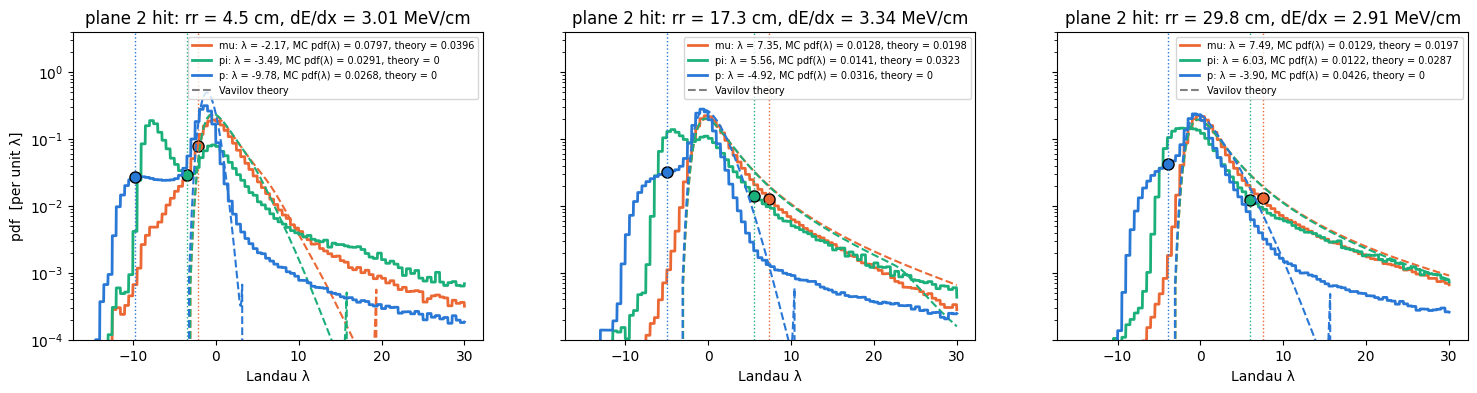

In [56]:
from scipy.stats import norm

def vavilov_lam_pdf(x, k, b):
    """Analytic pdf(lambda_L | kappa, beta2), same regime split as table_maker:
    Landau below kappa = 0.01, Vavilov up to 10, Gaussian (Vavilov's mean and variance) above."""
    if k < 0.01:
        return np.array([ROOT.Math.landau_pdf(xi) for xi in x])
    if k <= 10:
        vav = ROOT.Math.VavilovAccurate(k, b)
        return np.array([vav.Pdf(xi) for xi in x])
    return norm.pdf(x, np.euler_gamma - 1 - np.log(k) - b, np.sqrt((1 - b / 2) / k))

hits  = planes[2]
used  = np.flatnonzero(hits["usable"])
picks = used[[len(used) // 10, len(used) // 2, 9 * len(used) // 10]]   # 10%, 50% and 90% of the way along the track
lam_grid = np.linspace(-15, 30, 1500)

fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for i, a in zip(picks, ax):
    rr, dedx, pitch = hits["rr"][i], hits["dedx"][i], hits["pitch"][i]
    for hyp in llpid.HYPS:
        KE    = llpid._ke_from_rr(llpid._ke_table(hyp), rr)
        table = llpid._table_for(tables_bare, hits["plane"], hyp)
        xi_per_cm, kappa, beta2, mpv_shift = llpid._pdf_params(KE, llpid.MASS[hyp], pitch)
        lam = float(np.clip((dedx - mpv_shift) / xi_per_cm, -50.0, 100.0))   # this hit's Landau lambda under hyp

        kap = np.full_like(lam_grid, kappa)
        bet = np.full_like(lam_grid, beta2)
        curve = llpid._lookup_binned(lam_grid, kap, bet, table)                              # MC pdf(lambda | kappa, beta2)
        value = float(llpid._lookup_binned(np.array([lam]), kap[:1], bet[:1], table)[0])     # where the hit lands on it

        theory     = vavilov_lam_pdf(lam_grid, float(kappa), float(beta2))                   # analytic pdf at the same (kappa, beta2)
        theory_val = float(vavilov_lam_pdf([lam], float(kappa), float(beta2))[0])

        a.plot(lam_grid, curve, color=COLOR[hyp], lw=2,
               label=f"{hyp}: λ = {lam:.2f}, MC pdf(λ) = {value:.3g}, theory = {theory_val:.3g}")
        a.plot(lam_grid, theory, color=COLOR[hyp], lw=1.5, ls="--")
        a.plot(lam, value, "o", ms=8, color=COLOR[hyp], markeredgecolor="k")
        a.axvline(lam, color=COLOR[hyp], lw=1, ls=":")
    a.plot([], [], color="gray", lw=1.5, ls="--", label="Vavilov theory ")
    a.set(xlabel="Landau λ", yscale="log", ylim=(1e-4, 4),
          title=f"plane {hits['plane']} hit: rr = {rr:.1f} cm, dE/dx = {dedx:.2f} MeV/cm")
    a.legend(fontsize=7)
ax[0].set_ylabel("pdf  [per unit λ]")
plt.show()


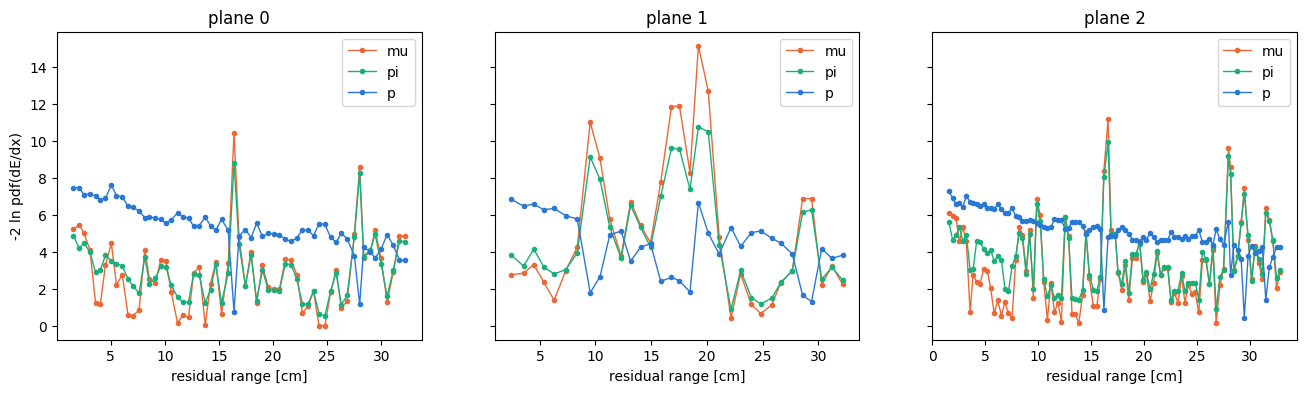

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for plane, a in enumerate(ax):
    for hyp in llpid.HYPS:
        h = per_hit[hyp][per_hit[hyp]["plane"] == plane]
        a.plot(h["rr"], h["-2ln(pdf)"], "o-", ms=3, lw=1, color=COLOR[hyp], label=hyp)
    a.set(xlabel="residual range [cm]", title=f"plane {plane}")
    a.legend()
ax[0].set_ylabel("-2 ln pdf(dE/dx)"); 
plt.show()


In [58]:
for hyp in llpid.HYPS:
    print(hyp)
    for hits in planes:
        by_hand = per_hit[hyp].loc[per_hit[hyp]["plane"] == hits["plane"], "-2ln(pdf)"].sum()
        n, ell_plane = llpid._track_ell(hits, tables_bare, hyp)
        print(f"   plane {hits['plane']}: {int(n[0]):4d} hits   by hand {by_hand:9.2f}   _track_ell   {ell_plane[0]:9.2f}")
    by_hand = per_hit[hyp]["-2ln(pdf)"].sum()
    print(f"   all planes        by hand {by_hand:9.2f}   _ell_at_zero {llpid._ell_at_zero(planes, tables_bare, hyp)[0]:9.2f}")

llpid.likelihood(hitdfs, rrcorr=False, params=params)


mu
   plane 0:   60 hits   by hand    168.24   _track_ell      168.24
   plane 1:   33 hits   by hand    171.40   _track_ell      171.40
   plane 2:   95 hits   by hand    306.65   _track_ell      306.65
   all planes        by hand    646.28   _ell_at_zero    646.28
pi
   plane 0:   60 hits   by hand    175.52   _track_ell      175.52
   plane 1:   33 hits   by hand    159.38   _track_ell      159.38
   plane 2:   95 hits   by hand    342.54   _track_ell      342.54
   all planes        by hand    677.44   _ell_at_zero    677.44
p
   plane 0:   60 hits   by hand    318.45   _track_ell      318.45
   plane 1:   33 hits   by hand    143.16   _track_ell      143.16
   plane 2:   95 hits   by hand    483.52   _track_ell      483.52
   all planes        by hand    945.13   _ell_at_zero    945.13


,,,,ell0_mu,ell0_pi,ell0_p,nhits_mu,nhits_pi,nhits_p,version
__ntuple,entry,rec.slc..index,rec.slc.reco.pfp..index,,,,,,,
6,1,0,1,646.281884,677.44166,945.12789,188.0,188.0,188.0,v0


# 2. Residual Range Corrected Likelihood

In [59]:
from matplotlib.lines import Line2D

tables = llpid._load_tables(params["tables"])
priors, dl_min = llpid._load_priors(params["prior_file"])
n_tracks = max(int(np.max(h["tid"])) for h in planes) + 1
DIRS = {False: "forward", True: "reversed"}

scan = {}
for hyp in llpid.HYPS:
    dls = np.arange(dl_min[hyp], params["scan_max"], 1.0)
    prior_term = llpid._prior_charge(priors[hyp], dls)
    scan[hyp] = {"dl": dls, "prior": prior_term}
    for rev in DIRS:
        flip = np.ones(n_tracks, bool) if rev else None   # reversed: rr -> rr_max - rr, as in llpid._scan
        data_term = np.array([sum(np.nan_to_num(llpid._track_ell(hits, tables, hyp, offset=dl, flipped=flip)[1][0])
                                  for hits in planes) for dl in dls])
        scan[hyp][rev] = {"data": data_term, "total": data_term + prior_term}

    # same orientation rule as llpid._orientation: reversed must win by more than flip_margin
    fwd_min, rev_min = scan[hyp][False]["total"].min(), scan[hyp][True]["total"].min()
    scan[hyp]["chosen"] = bool(params["allow_flip"] and (fwd_min - rev_min) > params["flip_margin"])

    for rev, dname in DIRS.items():
        s = scan[hyp][rev]
        best = np.argmin(s["total"])
        print(f"{hyp:>2} {dname:>8}  dL = 0: {s['data'][dls == 0][0]:8.2f}    best dL = {dls[best]:6.1f} cm:  "
              f"{s['data'][best]:8.2f} hits + {prior_term[best]:5.2f} prior = {s['total'][best]:8.2f}")
    print(f"{hyp:>2}  fwd - rev = {fwd_min - rev_min:+.2f} (margin {params['flip_margin']}) -> {DIRS[scan[hyp]['chosen']]}\n")


mu  forward  dL = 0:   646.28    best dL =   -1.0 cm:    640.63 hits +  1.85 prior =   642.49
mu reversed  dL = 0:   759.89    best dL =    4.0 cm:    723.75 hits +  4.13 prior =   727.89
mu  fwd - rev = -85.40 (margin 25.0) -> forward

pi  forward  dL = 0:   519.54    best dL =    0.0 cm:    519.54 hits +  0.00 prior =   519.54
pi reversed  dL = 0:   706.73    best dL =    6.0 cm:    635.25 hits +  8.93 prior =   644.18
pi  fwd - rev = -124.64 (margin 25.0) -> forward

 p  forward  dL = 0:  1782.94    best dL =   59.0 cm:    304.85 hits + 16.94 prior =   321.79
 p reversed  dL = 0:  1625.07    best dL =   70.0 cm:    404.70 hits + 17.42 prior =   422.13
 p  fwd - rev = -100.33 (margin 25.0) -> forward



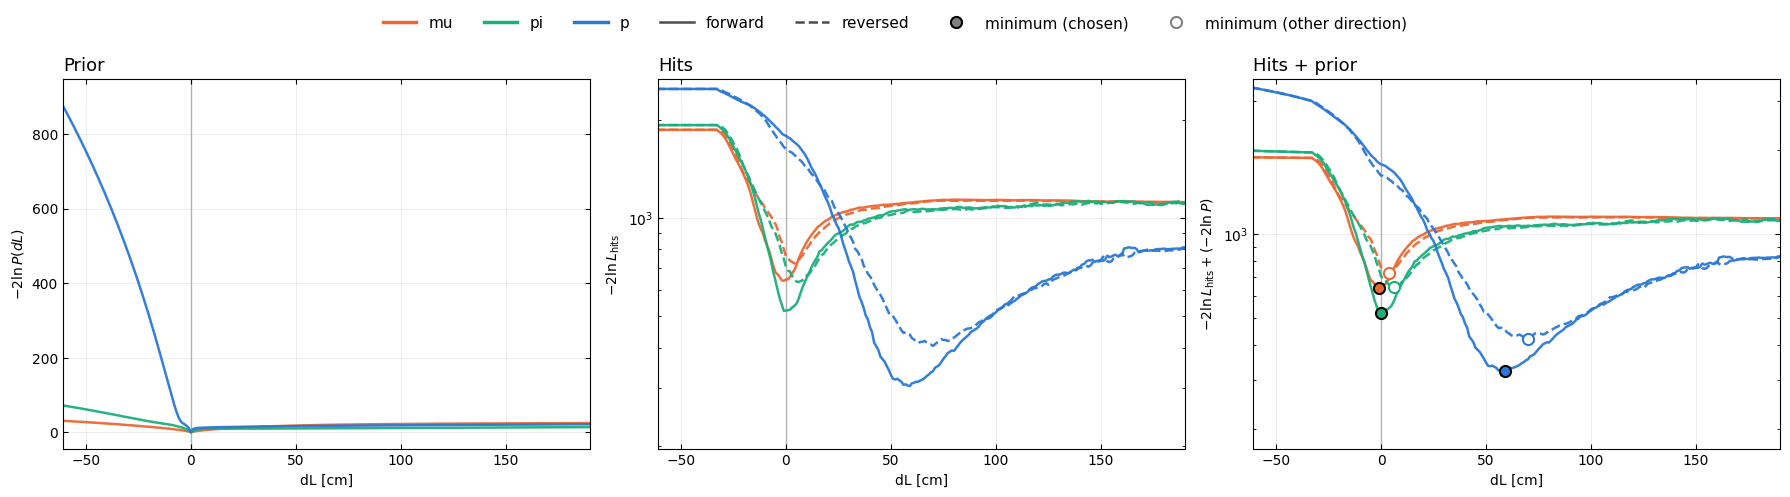

In [60]:

def plot_scan(scan, xlim=None, pad=(60, 120)):
    """prior | hits | hits + prior vs dL; zoomed on the minima unless xlim is given"""
    bests = [scan[h]["dl"][np.argmin(scan[h][r]["total"])] for h in llpid.HYPS for r in DIRS]
    if xlim is None:
        dl_all = scan[llpid.HYPS[0]]["dl"]
        xlim = (max(min(bests) - pad[0], dl_all.min()), min(max(bests) + pad[1], dl_all.max()))

    fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
    panels = [("prior", r"$-2\ln P(dL)$", "Prior"),
              ("data",  r"$-2\ln L_{\rm hits}$", "Hits"),
              ("total", r"$-2\ln L_{\rm hits} + (-2\ln P)$", "Hits + prior")]
    for a, (key, ylabel, title) in zip(ax, panels):
        lo, hi = np.inf, -np.inf
        for hyp in llpid.HYPS:
            s = scan[hyp]
            win = (s["dl"] >= xlim[0]) & (s["dl"] <= xlim[1])
            for rev, ls in [(False, "-"), (True, "--")]:
                if key == "prior" and rev:
                    continue                      # prior is the same in both directions
                y = s["prior"] if key == "prior" else s[rev][key]
                a.plot(s["dl"], y, color=COLOR[hyp], lw=1.8, ls=ls, alpha=0.95)
                lo, hi = min(lo, y[win].min()), max(hi, y[win].max())
                if key == "total":
                    i = np.argmin(s[rev]["total"])
                    chosen = rev == s["chosen"]
                    a.plot(s["dl"][i], y[i], "o", ms=8, zorder=5, mew=1.5,
                           mfc=COLOR[hyp] if chosen else "white", mec="k" if chosen else COLOR[hyp])
        span = hi - lo
        a.set_ylim(lo - 0.05 * span, hi + 0.08 * span)
        a.axvline(0, color="0.7", lw=1, zorder=0)
        a.set(xlim=xlim, xlabel="dL [cm]", ylabel=ylabel)
        a.set_title(title, loc="left", fontsize=13)
        a.tick_params(which="both", direction="in", top=True, right=True)
        a.set_yscale("linear" if key == "prior" else "log")
        a.grid(alpha=0.25, lw=0.6)

    handles = ([Line2D([], [], color=COLOR[h], lw=2.5, label=h) for h in llpid.HYPS]
               + [Line2D([], [], color="0.3", lw=1.8, ls="-", label="forward"),
                  Line2D([], [], color="0.3", lw=1.8, ls="--", label="reversed"),
                  Line2D([], [], marker="o", ls="", ms=8, mfc="0.5", mec="k", mew=1.5, label="minimum (chosen)"),
                  Line2D([], [], marker="o", ls="", ms=8, mfc="white", mec="0.5", mew=1.5, label="minimum (other direction)")])
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, fontsize=11,
               bbox_to_anchor=(0.5, 1.0), handlelength=2.2)
    
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()



plot_scan(scan)                         # zoomed on the minima
# plot_scan(scan, xlim=(-600, 600))     # full scan range


coarse grid: 241 points from -600.0 to 600.0 cm in 5.0 cm steps
 forward: coarse min 60 cm,  fine grid 40..80 cm,  minimum dL = 59 cm, -2lnL = 321.79   (dL = 0: 1782.94)
reversed: coarse min 70 cm,  fine grid 50..90 cm,  minimum dL = 70 cm, -2lnL = 422.13   (dL = 0: 1625.07)
fwd - rev = -100.33  (margin 25.0)  ->  fit uses the forward direction


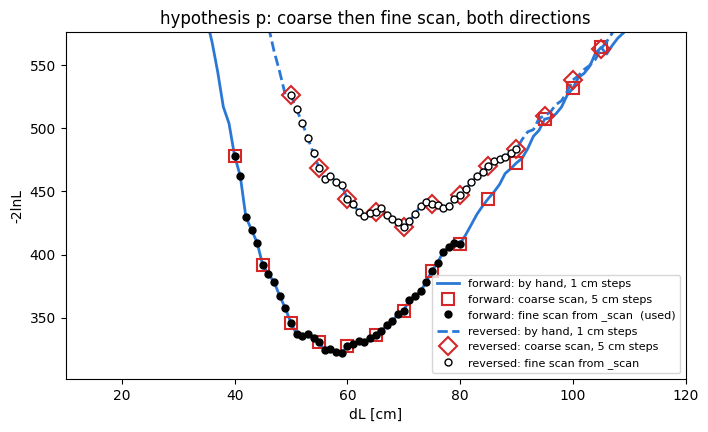

In [62]:
hyp    = TRUE_HYP
step   = params["scan_coarse"]
coarse = np.arange(dl_min[hyp], params["scan_max"] + step, step)
reach  = params["fine_steps"] * step
fine   = np.arange(-reach, reach + params["scan_fine"], params["scan_fine"])
n_trk  = len(tracks)

def coarse_surface(rev):
    """the coarse pass inside llpid._scan, which _scan does not return"""
    flip = np.full(n_trk, True) if rev else None
    ell = np.full((len(coarse), n_trk), np.nan)
    for g, d in enumerate(coarse):
        off = np.full(n_trk, d, float)
        tot, cnt = np.zeros(n_trk), np.zeros(n_trk)
        for hits in planes:
            n_p, raw_p = llpid._track_ell(hits, tables, hyp, off, flip)
            ok = n_p > 0
            tot[ok] += raw_p[ok]; cnt[ok] += n_p[ok]
        ell[g, cnt > 0] = tot[cnt > 0]
    return ell + llpid._prior_charge(priors[hyp], np.broadcast_to(coarse[:, None], ell.shape))

# both directions, then the llpid._orientation rule: reversed must win by more than flip_margin
fits = {rev: llpid._scan(planes, tables, hyp, coarse, fine, priors[hyp], n_trk, flipped=rev) for rev in DIRS}
coarse_ell = {rev: coarse_surface(rev) for rev in DIRS}
best = {rev: np.nanmin(f[0][:, 0]) for rev, f in fits.items()}
rev_fit = bool(params["allow_flip"] and best[False] - best[True] > params["flip_margin"])

print("coarse grid:", len(coarse), "points from", coarse[0], "to", coarse[-1], "cm in", step, "cm steps")
for rev, (fine_ell, fine_dl, zero_ell) in fits.items():
    i = np.nanargmin(fine_ell[:, 0])
    print(f"{DIRS[rev]:>8}: coarse min {coarse[np.nanargmin(coarse_ell[rev][:, 0])]:.0f} cm,  "
          f"fine grid {fine_dl[0, 0]:.0f}..{fine_dl[-1, 0]:.0f} cm,  minimum dL = {fine_dl[i, 0]:.0f} cm, "
          f"-2lnL = {fine_ell[i, 0]:.2f}   (dL = 0: {zero_ell[0]:.2f})")
print(f"fwd - rev = {best[False] - best[True]:+.2f}  (margin {params['flip_margin']})  ->  fit uses the {DIRS[rev_fit]} direction")

s = scan[hyp]
plt.figure(figsize=(8, 4.5))
lo, hi = [], []
for rev, ls, mk in [(False, "-", "s"), (True, "--", "D")]:
    fine_ell, fine_dl, _ = fits[rev]
    used = rev == rev_fit
    plt.plot(s["dl"], s[rev]["total"], color=COLOR[hyp], lw=2, ls=ls, label=f"{DIRS[rev]}: by hand, 1 cm steps")
    plt.plot(coarse, coarse_ell[rev][:, 0], mk, ms=9, mec="tab:red", mfc="none", mew=1.5,
             label=f"{DIRS[rev]}: coarse scan, {step:g} cm steps")
    plt.plot(fine_dl[:, 0], fine_ell[:, 0], "o", ms=5, mec="k", mfc="k" if used else "white",
             label=f"{DIRS[rev]}: fine scan from _scan" + ("  (used)" if used else ""))
    lo.append(fine_dl[0, 0]); hi.append(fine_dl[-1, 0])
ells = np.concatenate([fits[r][0][:, 0] for r in DIRS])
plt.xlim(min(lo) - 30, max(hi) + 30)
plt.ylim(np.nanmin(ells) - 20, np.nanmax(ells) + 50)
plt.xlabel("dL [cm]"); plt.ylabel("-2lnL")
plt.title(f"hypothesis {hyp}: coarse then fine scan, both directions")
plt.legend(fontsize=8)
plt.show()


Check the flatness parameters to see if fits are kept: 

In [ ]:
for rev, dname in DIRS.items():
    ell = fits[rev][0]
    edge_lo, edge_hi = llpid._well_edges(ell)
    ell_min = np.nanmin(ell, axis=0)
    rise_lo, rise_hi = (edge_lo - ell_min)[0], (edge_hi - ell_min)[0]
    flat = rise_lo < params["flat_abs"] or rise_hi < params["flat_abs"]
    print(f"{dname:>8}: left rise {rise_lo:8.2f}   right rise {rise_hi:8.2f}   "
          f"(flat_abs {params['flat_abs']:g})  ->  {'flattened, dL = 0' if flat else 'fit kept'}")



 forward: left rise   118.05   right rise    82.14   (flat_abs 10)  ->  fit kept
reversed: left rise    81.36   right rise    56.13   (flat_abs 10)  ->  fit kept


Check if the reverse direction wins the orientation:

In [ ]:
for rev, dname in DIRS.items():
    ell, dl, _ = fits[rev]
    i = np.nanargmin(ell[:, 0])
    print(f"{dname:<8} best -2lnL {ell[i, 0]:8.2f} at dL = {dl[i, 0]:6.1f} cm")
fwd_min, rev_min = best[False], best[True]
print(f"fwd - rev = {fwd_min - rev_min:+.2f};  reversed has to win by flip_margin = {params['flip_margin']}:  "
      f"flip = {fwd_min - rev_min > params['flip_margin']}")


forward  best -2lnL   321.79 at dL =   59.0 cm
reversed best -2lnL   422.13 at dL =   70.0 cm
fwd - rev = -100.33;  reversed has to win by flip_margin = 25.0:  flip = False


Check the fits for all parameters, which match the optimal fit from above, showing that the code produced in this document matches the process performed in the likelihood algorithm

In [67]:
fits = llpid._fit_dl(planes, tables, priors, dl_min, n_hits, params, llpid.HYPS)
pd.DataFrame({hyp: {name: fits[hyp][name][0] for name in ("cost", "dl", "flip", "fitok", "flattened", "onedge")}
              for hyp in llpid.HYPS})


,mu,pi,p
cost,642.488541,519.543154,321.793456
dl,-1.0,0.0,59.0
flip,False,False,False
fitok,True,True,True
flattened,False,False,False
onedge,False,False,False


Comparing the choices of fits using different PID metrics; note chi2_pion was not included in the cafpyana branches when this sample was made. 

In [68]:
lldf = llpid.likelihood(hitdfs, rrcorr=True, params=params)
chi2 = evt["pfp", "trk", "chi2pid", "I2"].loc[trk]          # collection plane only, chi2 / ndof
CHI2 = {"p": "chi2_proton", "mu": "chi2_muon", "pi": "chi2_pion"}
pd.DataFrame({"ell0 (bare)":  [lldf["ell0_" + h].iloc[0] for h in llpid.HYPS],
              "ell (dL fit)": [lldf["ell_" + h].iloc[0] for h in llpid.HYPS],
              "dL [cm]":      [lldf["dl_" + h].iloc[0] for h in llpid.HYPS],
              f"chi2/ndof (ndof {int(chi2['pid_ndof'].squeeze())})":
                              [chi2[CHI2[h]].squeeze() if CHI2[h] in chi2 else np.nan for h in llpid.HYPS]},
             index=llpid.HYPS)


,ell0 (bare),ell (dL fit),dL [cm],chi2/ndof (ndof 77)
mu,646.281884,642.488541,-1.0,3.902437
pi,677.441660,519.543154,0.0,NaN
p,945.127890,321.793456,59.0,101.537971


Showing the result of the residual range correction:

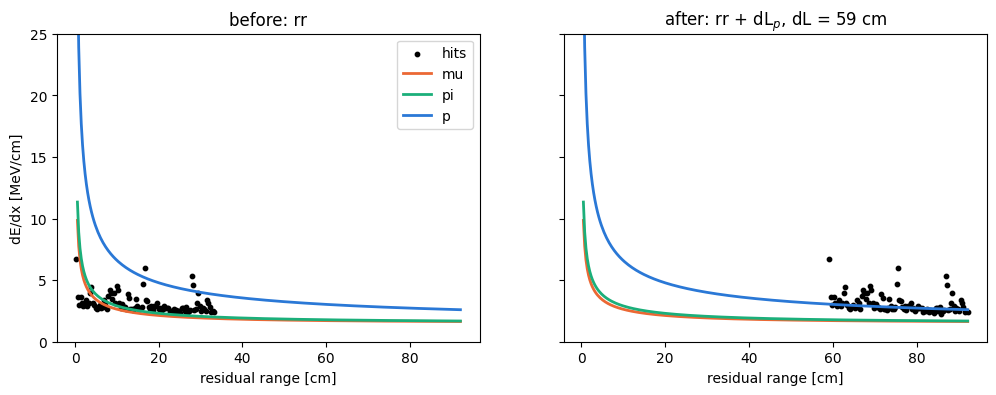

In [16]:
hdf  = hitdfs[2]
dl   = lldf["dl_" + TRUE_HYP].iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, rr, title in [(ax[0], hdf["rr"], "before: rr"), (ax[1], llpid.rr_corr(hdf, lldf, TRUE_HYP), f"after: rr + dL$_{{{TRUE_HYP}}}$, dL = {dl:.0f} cm")]:
    a.scatter(rr, hdf["dedx"], s=10, c="k", label="hits")
    for h in llpid.HYPS:
        rr_grid = np.linspace(0.5, hdf["rr"].max()+dl, 300)
        KE = llpid._ke_from_rr(llpid._ke_table(h), rr_grid)
        a.plot(rr_grid, llpid._pdf_params(KE, llpid.MASS[h], pitch)[3], color=COLOR[h], lw=2, label=h)
    a.set(xlabel="residual range [cm]", title=title, ylim=(0, 25))
ax[0].set_ylabel("dE/dx [MeV/cm]"); ax[0].legend()
plt.show()


## Failing Range Correction and Track Flipping Margin

In [24]:
PDG2HYP   = {13: "mu", 211: "pi", 2212: "p"}
STOP_PROC = [ 41, 45, 46, 54]    # caf::G4ProcessID: Decay, muMinusCaptureAtRest, hBertini/hFritiofCaptureAtRest, hIoni


In [26]:
def true_reversed(evt):
    """reversed: the reco start is nearer the true end than the true start.
    match_cm: reco start to the nearer true end point -- large means neither label can be trusted"""
    xyz = lambda *c: np.stack([evt[(*c, a)].to_numpy(float) for a in "xyz"], axis=1)
    reco_start = xyz("pfp", "trk", "start")
    d_start = np.linalg.norm(reco_start - xyz("pfp", "trk", "truth", "p", "start"), axis=1)
    d_end   = np.linalg.norm(reco_start - xyz("pfp", "trk", "truth", "p", "end"), axis=1)
    return pd.DataFrame({"reversed": d_end < d_start, "match_cm": np.minimum(d_start, d_end)}, index=evt.index)


def select_tracks(evt, match_cm=5.0):
    """neutrino-induced (not cosmic), contained, stopping true mu / pi / p whose reco start sits on a true end point"""
    t   = evt["pfp", "trk", "truth", "p"]
    hyp = np.abs(t["pdg"]).map(PDG2HYP)
    ori = true_reversed(evt)
    keep = ((t["interaction_id"] >= 0) & (t["cont_tpc"] == 1) & t["end_process"].isin(STOP_PROC) & hyp.notna() & (ori["match_cm"] < match_cm))
    return pd.DataFrame({"hyp": hyp, "reversed": ori["reversed"]})[keep]


def scan_tracks(hitdfs, params=llpid.LLPID_PARAMS):
    """the slow part of llpid.likelihood, run once: per hypothesis and direction the well rise on each side,
    the best dL and its -2lnL, and the dL = 0 -2lnL. flat_abs / flip_margin are applied afterwards by apply_cuts"""
    tables = llpid._load_tables(params["tables"])
    priors, dl_min = llpid._load_priors(params["prior_file"])
    tracks = llpid._track_index(hitdfs)
    planes = [llpid._prepare_plane(df, tracks, llpid._plane_of(df, i, len(hitdfs)), "dedx", params)  for i, df in enumerate(hitdfs)]
    rr_max = np.nanmedian([llpid._per_track_max(h, h["rr"]) for h in planes], axis=0)
    for h in planes:                                               # same shared rr_max as llpid.likelihood
        h["rr_max"] = rr_max[h["tid"]]
        h["usable"] = llpid._usable_hits(h, params)
        h["n_usable"] = llpid._per_track_sum(h, h["usable"])

    n, cols = len(tracks), np.arange(len(tracks))
    step = float(params["scan_coarse"])
    reach = float(params["fine_steps"]) * step
    fine = np.arange(-reach, reach + params["scan_fine"], params["scan_fine"])
    out = {"nhits": sum(h["n_usable"] for h in planes)}
    for hyp in llpid.HYPS:
        coarse = np.arange(dl_min[hyp], params["scan_max"] + step, step)
        for rev, tag in ((False, "fwd"), (True, "rev")):
            ell, dl, zero = llpid._scan(planes, tables, hyp, coarse, fine, priors[hyp], n, rev)
            lo, hi = llpid._well_edges(ell)
            ell_min = np.nanmin(np.where(np.isnan(ell), np.inf, ell), axis=0)
            total = np.where((dl < dl_min[hyp]) | (dl > params["scan_max"]), np.inf, ell)
            k = np.argmin(total, axis=0)
            out[f"rise_lo_{hyp}_{tag}"], out[f"rise_hi_{hyp}_{tag}"] = lo - ell_min, hi - ell_min
            out[f"dl_{hyp}_{tag}"], out[f"cost_{hyp}_{tag}"], out[f"zero_{hyp}_{tag}"] = dl[k, cols], total[k, cols], zero
    return pd.DataFrame(out, index=tracks)

def apply_cuts(scan, flat_abs, flip_margin, params=llpid.LLPID_PARAMS):
    """llpid's flatten / flip / fallback decisions on a stored scan -- instant. Per hypothesis: ell (as llpid.likelihood
    returns it), dl, flip, and delta = cost_fwd - cost_rev after flattening (llpid flips when delta > flip_margin).
    orient_shared is not handled (default False)"""
    p = dict(params, flat_abs=flat_abs, flip_margin=flip_margin)
    enough = scan["nhits"].to_numpy() >= p["min_hits"]
    out = {}
    for h in llpid.HYPS:
        best = {}
        for rev, tag in ((False, "fwd"), (True, "rev")):
            flat = (scan[f"rise_lo_{h}_{tag}"].to_numpy() < flat_abs) | (scan[f"rise_hi_{h}_{tag}"].to_numpy() < flat_abs)
            zero = scan[f"zero_{h}_{tag}"].to_numpy()
            best[rev] = {"dl": np.where(flat, 0.0, scan[f"dl_{h}_{tag}"].to_numpy()),
                         "cost": np.where(flat, zero, scan[f"cost_{h}_{tag}"].to_numpy()),
                         "zero_ell": zero, "flattened": flat}
        flip = llpid._orientation(best, p) if p["allow_flip"] else np.zeros(len(scan), bool)
        fit = llpid._apply_orientation(best, flip & enough, enough, p)
        out["ell_" + h], out["dl_" + h], out["flip_" + h] = fit["cost"], fit["dl"], fit["flip"]
        out["delta_" + h] = best[False]["cost"] - best[True]["cost"]
    return pd.DataFrame(out, index=scan.index)



In [ ]:
import glob
from concurrent.futures import ProcessPoolExecutor

N_FILES, N_WORKERS = 500, 8
FILES = sorted(glob.glob("/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/"
                         "100k_MC_trkhit_run1gen2_*.df"))[:N_FILES]

def one_file(f):
    out = []
    for s in range(get_n_split(f)):
        sel = select_tracks(pd.read_hdf(f, key=f"/evt_{s}"))
        if len(sel) == 0:
            continue
        hits = [pd.read_hdf(f, key=f"/hit{p}_{s}") for p in range(3)]
        hits = [h[h.index.droplevel(-1).isin(sel.index)] for h in hits]
        # (__ntuple, entry, ...) repeats between files: prepend file and split so every track is unique
        out.append(pd.concat({(f, s): sel.join(scan_tracks(hits), how="inner")}, names=["file", "split"]))
    return pd.concat(out) if out else None

with ProcessPoolExecutor(N_WORKERS) as ex:
    scan = pd.concat([r for r in ex.map(one_file, FILES) if r is not None])
scan = scan[scan["nhits"] >= llpid.LLPID_PARAMS["min_hits"]]       # llpid never fits these: always dL = 0, never flipped
scan.to_pickle("llpid_scan_stopping.pkl")
print(len(scan), "tracks;", dict(scan["hyp"].value_counts()), "; reversed:", dict(scan.groupby("hyp")["reversed"].mean().round(3)))


23131 tracks; {'p': 14666, 'mu': 7961, 'pi': 504} ; reversed: {'mu': 0.084, 'p': 0.052, 'pi': 0.087}


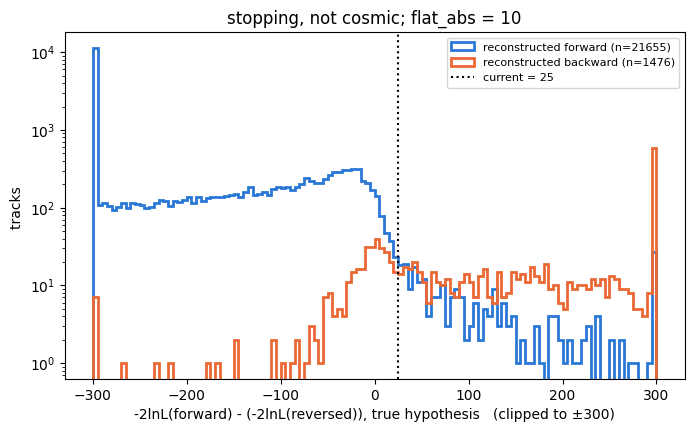

flip_margin   0: backward flipped 0.881   forward flipped 0.0269   correctly oriented 0.9672
flip_margin  10: backward flipped 0.834   forward flipped 0.0167   correctly oriented 0.9738
flip_margin  25: backward flipped 0.792   forward flipped 0.0117   correctly oriented 0.9757
flip_margin  40: backward flipped 0.760   forward flipped 0.0096   correctly oriented 0.9757
flip_margin  60: backward flipped 0.725   forward flipped 0.0076   correctly oriented 0.9754
flip_margin 100: backward flipped 0.665   forward flipped 0.0052   correctly oriented 0.9738


In [32]:
FLAT_ABS = llpid.LLPID_PARAMS["flat_abs"]
res      = apply_cuts(scan, FLAT_ABS, np.inf)
hyp      = scan["hyp"].to_numpy()
delta    = np.select([hyp == h for h in llpid.HYPS], [res["delta_" + h].to_numpy() for h in llpid.HYPS])   # under the true hypothesis
rev      = scan["reversed"].to_numpy()

bins = np.linspace(-300, 300, 121)
plt.figure(figsize=(8, 4.5))
for sel, c, name in [(~rev, "#2a78d6", "reconstructed forward"), (rev, "#eb6834", "reconstructed backward")]:
    plt.hist(np.clip(delta[sel], bins[0], bins[-1]), bins=bins, histtype="step", lw=2, color=c, density=False,
             label=f"{name} (n={sel.sum()})")
plt.axvline(llpid.LLPID_PARAMS["flip_margin"], color="k", ls=":", label=f"current = {llpid.LLPID_PARAMS['flip_margin']:g}")
plt.yscale("log")
plt.xlabel("-2lnL(forward) - (-2lnL(reversed)), true hypothesis   (clipped to ±300)"); plt.ylabel("tracks ")
plt.title(f"stopping, not cosmic; flat_abs = {FLAT_ABS:g}")
plt.legend(fontsize=8); plt.show()

for m in (0, 10, 25, 40, 60, 100):
    print(f"flip_margin {m:>3}: backward flipped {np.mean(delta[rev] > m):.3f}   forward flipped {np.mean(delta[~rev] > m):.4f}   "
          f"correctly oriented {np.mean(np.where(rev, delta > m, delta <= m)):.4f}")



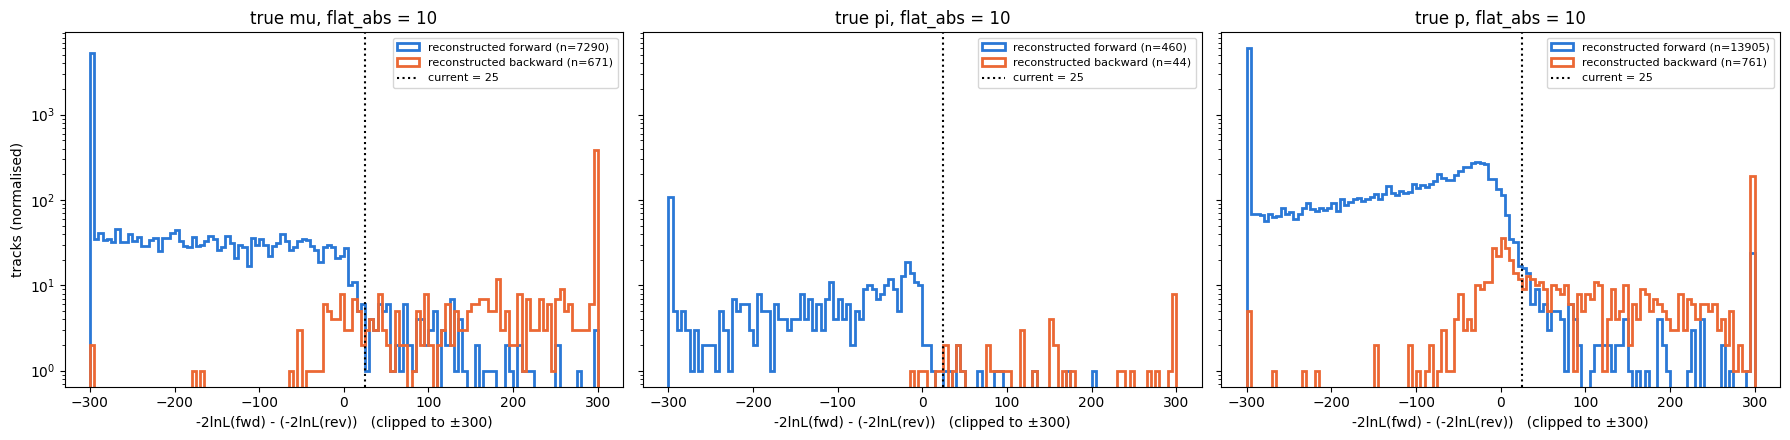

true mu  (671 backward / 7290 forward;  never flip: 0.9157 correct)
   flip_margin   0: backward flipped 0.942   forward flipped 0.0209   correctly oriented 0.9760
   flip_margin  10: backward flipped 0.933   forward flipped 0.0158   correctly oriented 0.9799
   flip_margin  25: backward flipped 0.912   forward flipped 0.0128   correctly oriented 0.9809
   flip_margin  40: backward flipped 0.897   forward flipped 0.0117   correctly oriented 0.9807
   flip_margin  60: backward flipped 0.876   forward flipped 0.0092   correctly oriented 0.9812
   flip_margin 100: backward flipped 0.839   forward flipped 0.0062   correctly oriented 0.9808
true pi  (44 backward / 460 forward;  never flip: 0.9127 correct)
   flip_margin   0: backward flipped 0.955   forward flipped 0.0348   correctly oriented 0.9643
   flip_margin  10: backward flipped 0.932   forward flipped 0.0261   correctly oriented 0.9702
   flip_margin  25: backward flipped 0.886   forward flipped 0.0239   correctly oriented 0.9683
  

In [31]:
FLAT_ABS = llpid.LLPID_PARAMS["flat_abs"]
res      = apply_cuts(scan, FLAT_ABS, np.inf)
hyp      = scan["hyp"].to_numpy()
delta    = np.select([hyp == h for h in llpid.HYPS], [res["delta_" + h].to_numpy() for h in llpid.HYPS])   # under the true hypothesis
rev      = scan["reversed"].to_numpy()

bins = np.linspace(-300, 300, 121)
fig, ax = plt.subplots(1, len(llpid.HYPS), figsize=(18, 4.5), sharey=True)
for a, h in zip(ax, llpid.HYPS):
    is_h = hyp == h
    for sel, c, name in [(~rev, "#2a78d6", "reconstructed forward"), (rev, "#eb6834", "reconstructed backward")]:
        m = is_h & sel
        if m.sum():
            a.hist(np.clip(delta[m], bins[0], bins[-1]), bins=bins, histtype="step", lw=2, color=c, density=False,
                   label=f"{name} (n={m.sum()})")
    a.axvline(llpid.LLPID_PARAMS["flip_margin"], color="k", ls=":", label=f"current = {llpid.LLPID_PARAMS['flip_margin']:g}")
    a.set(yscale="log", xlabel="-2lnL(fwd) - (-2lnL(rev))   (clipped to ±300)", title=f"true {h}, flat_abs = {FLAT_ABS:g}")
    a.legend(fontsize=8)
ax[0].set_ylabel("tracks (normalised)")
plt.tight_layout(); plt.show()

for h in llpid.HYPS:
    is_h = hyp == h
    print(f"true {h}  ({np.sum(is_h & rev)} backward / {np.sum(is_h & ~rev)} forward;  never flip: {np.mean(~rev[is_h]):.4f} correct)")
    for m in (0, 10, 25, 40, 60, 100):
        print(f"   flip_margin {m:>3}: backward flipped {np.mean(delta[is_h & rev] > m):.3f}   "
              f"forward flipped {np.mean(delta[is_h & ~rev] > m):.4f}   "
              f"correctly oriented {np.mean(np.where(rev, delta > m, delta <= m)[is_h]):.4f}")


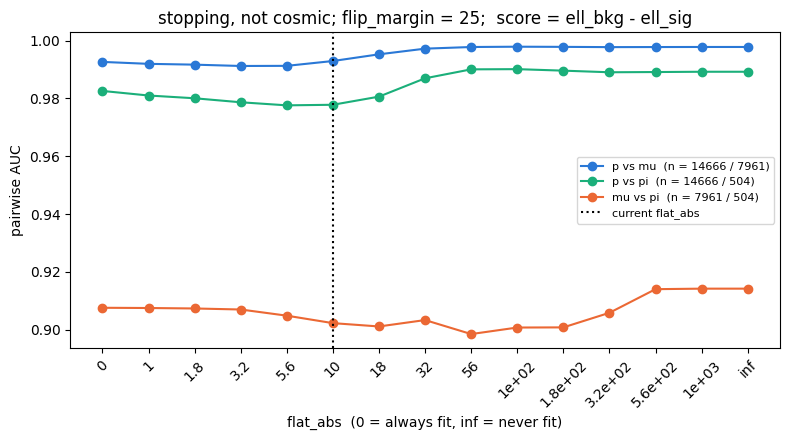

flat_abs     p/mu      p/pi     mu/pi
       0   0.9926    0.9826    0.9076
       1   0.9919    0.9810    0.9075
    1.78   0.9917    0.9800    0.9074
    3.16   0.9912    0.9787    0.9070
    5.62   0.9912    0.9776    0.9049
      10   0.9929    0.9778    0.9023
    17.8   0.9952    0.9806    0.9011
    31.6   0.9972    0.9869    0.9034
    56.2   0.9978    0.9900    0.8985
     100   0.9979    0.9901    0.9008
     178   0.9978    0.9896    0.9008
     316   0.9977    0.9890    0.9059
     562   0.9977    0.9891    0.9140
   1e+03   0.9978    0.9892    0.9142
     inf   0.9978    0.9892    0.9142


In [ ]:
from scipy import stats

stop_scan = pd.read_pickle("llpid_scan_stopping.pkl")             # tuning scan; `scan` is the by-hand dL scan dict in section 2

def auc(sig, bkg):
    """rank AUC: probability a random signal track scores above a random background track (ties count half)"""
    sig, bkg = sig[np.isfinite(sig)], bkg[np.isfinite(bkg)]
    r = stats.rankdata(np.r_[sig, bkg])
    return (r[:len(sig)].sum() - len(sig) * (len(sig) + 1) / 2) / (len(sig) * len(bkg))

FLIP_MARGIN = 25.0
FLATS = np.r_[0, np.logspace(0, 3, 13), np.inf]                   # 0 = always fit, inf = never fit
H     = np.array(llpid.HYPS)
hyp   = stop_scan["hyp"].to_numpy()


PAIRS = [("p", "mu"), ("p", "pi"), ("mu", "pi")]                  # (signal, background): score = ell_bkg - ell_sig
pair_auc = {pr: [] for pr in PAIRS}
for fa in FLATS:
    res = apply_cuts(stop_scan, fa, FLIP_MARGIN)
    for s, b in PAIRS:
        score = (res["ell_" + b] - res["ell_" + s]).to_numpy()
        pair_auc[s, b].append(auc(score[hyp == s], score[hyp == b]))

PCOL = {("p", "mu"): "#2a78d6", ("p", "pi"): "#1baf7a", ("mu", "pi"): "#eb6834"}
x = np.arange(len(FLATS))
plt.figure(figsize=(8, 4.5))
for (s, b), v in pair_auc.items():
    plt.plot(x, v, "o-", color=PCOL[s, b], label=f"{s} vs {b}  (n = {np.sum(hyp == s)} / {np.sum(hyp == b)})")
plt.axvline(np.argmin(np.abs(FLATS - llpid.LLPID_PARAMS["flat_abs"])), color="k", ls=":", label="current flat_abs")
plt.xticks(x, [f"{f:.2g}" for f in FLATS], rotation=45)
plt.xlabel("flat_abs  (0 = always fit, inf = never fit)"); plt.ylabel("pairwise AUC")
plt.title(f"stopping, not cosmic; flip_margin = {FLIP_MARGIN:g};  score = ell_bkg - ell_sig")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'flat_abs':>8} " + "  ".join(f"{s + '/' + b:>8}" for s, b in PAIRS))
for i, fa in enumerate(FLATS):
    print(f"{fa:8.3g} " + "  ".join(f"{pair_auc[pr][i]:8.4f}" for pr in PAIRS))
